# EF5560 A01：从一张数据表到可核查的投资权重

这份 Notebook 是完整教学与唯一分析源码。你会依次完成 Q1 数据与基线、Q2 线性模型、Q3 随机森林、Q4 重要性、Q5 投资组合；不需要先运行旧脚本。每个代码格上方解释目的，下方解释输出、常见错误和理论。**按顺序逐格按 Shift+Enter；不要跳过前面的格子。** 蓝色/灰色文字格说明方法，带 `In [ ]` 的格子执行 Python；`[*]` 表示仍在运行。

第一次在 JupyterLab 打开：右上角选 **Python 3 (ipykernel)**。完整复现使用 **Kernel → Restart Kernel and Run All Cells…**。这会清掉旧变量，再从顶部运行；成功后代码执行序号应按运行顺序递增（Jupyter 扩展可能占用中间序号，不要求相邻），不能出现红色异常。运行完 Ctrl+S 保存结果。若从源码 ZIP 重做，先解压到新目录，只需在第一格指定官方 `student_release` 路径；其余格不用改。

数据、题意和评分来源：本地官方包内 `EF5560_ML_Investment_Project_2026.pdf` pp.1–4。数据是模拟数据，日期和股票名是标签。Canvas 旧核对记录截止为 2026-10-15 14:00 香港时间，PDF 写 12:00；内部按较早时刻。本地文件保留 **DRAFT** 与占位身份，只说明这是教学工作副本。2026-10-21 邮件知识库的既有 Canvas 核查记录显示：本人 ML Project 于 2026-10-12 13:01 已交、当时尚未评分。本次没有重查当前 Canvas，也没有证明本地副本等于已上传的附件。复习不要求重新提交。

| 问题 | 你要回答什么 | 交付 |
|---|---|---|
| Q1（10 分） | 数据有多少、目标是什么、如何防止未来信息泄漏 | 统计、Figure 1、零预测 |
| Q2（20 分） | OLS 与 LASSO 怎样选、系数怎样读 | Table 1–2、Figure 2 |
| Q3（15 分） | 森林更复杂，为什么未必更好 | 设置比较、补齐 Table 1 |
| Q4（15 分） | 固定模型依赖哪些输入，不能推出什么 | Figure 3–4 |
| Q5（15 分） | 预测最准确的模型是否最会选股 | Table 3、权重、Figure A1 拓展 |

实现信息占 5 分；隐藏期相对表现占 20 分，当前看不到收益，不能声称已取得这部分分数。下面的解释与类比属于笔记补充，实际数值由代码输出；没有把它们冒充课堂原话。

本次只修教学 Markdown，代码、已保存输出与执行计数原样保留；旧空内核运行及 ZIP 复现来自 2026-09-27 记录，不冒称今天重跑。格式按 2026-10-09 已核公告记录为最多 8 页含封面＋可选 1 页附录；10 月 5 日的 15 页邮件已由 10 月 6 日编辑更正替代。当前在线附件/评分另核。行政来源入口见同目录上级 notes/开始这里.md 与邮件库 EF5560 记录。

本教程从高中四则运算、百分数和简单代数开始；变量、函数和数组语法在用到时解释。学习后应能核时间划分、比较预测误差、解释固定模型的重要性、生成有约束的权重，并说明模拟验证结果与本人评分的区别。不要把示例检查替代真实团队核验。

### 0.1 只在这里设置数据路径


路径就是文件所在地址。`Path(...)` 把文字地址变成 Python 能拼接和检查的路径对象；`/` 在路径之间表示进入子目录。`=` 是给变量取名，`None` 表示暂未指定。本机保留 `DATA_DIR = None` 即自动定位；从源码 ZIP 运行时可改成 `Path(r"D:/你的目录/student_release")`。`r` 前缀使反斜杠按字面理解。

`WORK` 使用当前 Notebook 的工作目录。Jupyter 应从这个 `work` 文件夹启动；所有衍生结果写入其 `output/`，输入目录只读。下面的断言会在读数据前检查环境，避免在错误目录默默写文件。

In [3]:
from pathlib import Path
import sys

DATA_DIR = None  # 若移动到别处，只修改这一行；指定官方 student_release 文件夹。
WORK = Path.cwd().resolve()
if DATA_DIR is None:
    course = next(
        (p for p in [WORK, *WORK.parents] if (p / "course_files_export").is_dir()), None
    )
    assert course is not None, "请在第一格设置 DATA_DIR 为官方 student_release 目录"
    DATA_DIR = (
        course
        / "course_files_export/EF5560_ML_Investment_Project_2026_Student/student_release"
    )
RELEASE = Path(DATA_DIR).expanduser().resolve()
OUTPUT = WORK / "output"
assert (WORK / "safe_write.py").is_file(), "请从 Notebook 所在 work 目录启动 Jupyter"
for name in [
    "project_data_handout_2026.csv",
    "data_dictionary_2026.csv",
    "submission_template_2026.csv",
]:
    assert (RELEASE / name).is_file(), f"找不到输入文件：{RELEASE / name}"
OUTPUT.mkdir(exist_ok=True)
print("解释器：", sys.executable)
print("只读输入：", RELEASE)
print("结果目录：", OUTPUT)

解释器： D:\anaconda3\python.exe
只读输入： D:\上课资料\CityU\EF5560_Fintech_and_AI_in_Finance\course_files_export\EF5560_ML_Investment_Project_2026_Student\student_release
结果目录： D:\上课资料\CityU\EF5560_Fintech_and_AI_in_Finance\assignment\graded\A01-ml-investment\work\output


**运行后怎样读：** 本机解释器应为 `D:/anaconda3/python.exe`，输入应落在官方 `student_release`。出现 `AssertionError` 先看报错点名的路径，不要把原始数据复制进输出目录；出现 `NameError` 通常是跳格运行。**所以呢：** 一开始就确定输入输出边界，后面的分析才可复现。

### 0.2 导入工具，认识函数与参数


`import` 加载现有工具；`as np`/`as pd` 取短名。NumPy 处理数字数组，pandas 处理带列名的表（DataFrame），sklearn 训练模型，Matplotlib 画图。函数是给一组步骤取名字，例如 `print(...)`；括号中的值是参数，`name=value` 形式说明参数用途。

随机种子 `SEED` 固定为 2026；不改变已有分析设定。`PENALTIES` 是待比较的 8 个惩罚值，`FOREST_SETTINGS` 是 5 个参数字典组成的列表。字典用键名找值（如 `setting['max_depth']`），列表按从 0 开始的位置找元素。先看打印结果认识结构，Q2/Q3 再解释参数。

In [6]:
import csv, io, json, os
import numpy as np
import pandas as pd
import sklearn
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Image
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Lasso, LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler
from safe_write import atomic_write

SEED = 2026
PENALTIES = np.geomspace(1e-5, 1e-2, 8)
FOREST_SETTINGS = [
    {"max_depth": 5, "min_samples_leaf": 10},
    {"max_depth": 8, "min_samples_leaf": 10},
    {"max_depth": 12, "min_samples_leaf": 10},
    {"max_depth": 8, "min_samples_leaf": 25},
    {"max_depth": None, "min_samples_leaf": 25},
]
print("8 个 alpha：", PENALTIES)
print("5 组森林设置：", FOREST_SETTINGS)

8 个 alpha： [1.00000000e-05 2.68269580e-05 7.19685673e-05 1.93069773e-04
 5.17947468e-04 1.38949549e-03 3.72759372e-03 1.00000000e-02]
5 组森林设置： [{'max_depth': 5, 'min_samples_leaf': 10}, {'max_depth': 8, 'min_samples_leaf': 10}, {'max_depth': 12, 'min_samples_leaf': 10}, {'max_depth': 8, 'min_samples_leaf': 25}, {'max_depth': None, 'min_samples_leaf': 25}]


**运行后怎样读：** 应看到 8 个从 0.00001 到 0.01 的数和 5 组设置。`ModuleNotFoundError` 先检查是否选错 kernel，不要随意更换已验证的版本。`1e-5` 是 0.00001 的科学记数法。**所以呢：** 所有候选在模型比较前明示，结果不能靠事后隐去失败设置来美化。

### 0.3 保存文件是基础设施，分析会在后面逐步展开


`def` 定义函数，缩进部分是函数体；调用前不会执行。`save_csv(frame, name)` 的两个参数是表和文件名，`index=False` 避免把 DataFrame 的行号当成数据列。`save_png(fig, name)` 先写临时图，再替换目标；`atomic_write` 对文本做同样的原子替换，避免同步读到半个文件。

这些短函数只负责保存文件，不训练模型。统计指标、逐列替换、排名和组合选择在后面公开计算。CSV 保留计算精度，报告显示时再按 MSE 10 位、系数与 alpha 8 位、其他统计 6 位小数格式化。

In [9]:
def save_png(fig: plt.Figure, name: str) -> None:
    target = OUTPUT / name
    temp = OUTPUT / f".{name}"
    fig.savefig(temp, dpi=180, bbox_inches="tight", format="png")
    plt.close(fig)
    os.replace(temp, target)


def save_csv(frame: pd.DataFrame, name: str, *, index: bool = False) -> None:
    atomic_write(OUTPUT / name, frame.to_csv(index=index, float_format="%.10g"))

**运行后怎样读：** 这格只定义函数，没有打印是正常的。重新运行这一格只会重新定义函数；后续调用这些保存函数时才替换 `output/` 中同名结果，不会改官方数据。**所以呢：** 保持原文件名，让现有报告构建器仍能读到同一结果结构。

## Q1 · 先认识一行，再确定时间边界

一行是某只股票在某个预测周的记录。官方已把下一周收益对齐到本行，不能再 `shift()`。本节对应 brief p.1；理论对应课程 M01 金融数据、M02 样本外设计。

<details><summary>原题共同数据设定与 Q1 英文全文（brief p.1）</summary>

2026 Machine-Learning Investment Assignment. Instructor: Prof. Gavin Feng. Course weight: 20%. Team: Up to three. Release: After Class 4. Due: 15 October 2026. Submission deadline: 12:00 noon, Hong Kong time (UTC+8).

Overview. Forecast weekly stock excess returns and construct a long-only portfolio using the supplied simulated data. Compare OLS, LASSO, and either random forest or boosting in Q1–Q5.

Data and timing. The panel covers 260 simulated weeks for 80 stock labels from the July 2023 Hang Seng Index universe. Dates and names are labels; numerical observations are simulated, with stronger predictive signals than in real stock returns.

Training: Weeks 1–78, 6,240 stock-week rows, next-week returns visible. Validation: Weeks 79–104, 2,080 rows, visible. Private evaluation: Weeks 105–260, 12,480 rows, hidden.

Use "project_data_handout_2026.csv" or "project_data_handout_2026.xlsx" (identical 20,800 rows). The dictionary lists 17 dimensionless predictors: six market and eleven stock/sector signals. For example, momentum_short is simulated, not calculated from ret_next_week.

Predictors and rf_weekly are available at the forecast date. The next week’s total return, ret_next_week, is already aligned with that row; do not shift it. Predict $y=\mathrm{ret\_next\_week}-\mathrm{rf\_weekly}$. Use only the 17 predictors as inputs, excluding identifiers, dates, split labels, and outcomes.

Q1. Data and prediction benchmark (10 points)

- Sample counts and target statistics. Report stocks, weeks, and rows by split, plus the training target’s mean and sample standard deviation.
- Figure 1: Predictor correlations. Plot the training correlation matrix for all 17 predictors. Identify one strongly correlated pair and report its correlation.
- Time split and benchmark. Explain why random stock-week splits are unsuitable. Define the zero-excess-return forecast and calculate its validation MSE.

Hint. The zero-excess-return benchmark forecasts a total return of rf_weekly; it differs from Q5’s equal-weight portfolio. Pool the same 2,080 validation rows for every model:

$$
R^2_{\mathrm{OOS}}=1-\frac{\sum_i(y_i-\widehat y_i)^2}{\sum_i y_i^2}
$$

</details>

中文读题：每个分区都要给股票、周和行数；目标统计只算训练期。`already aligned` 直接决定不能再移收益行，`same 2,080` 决定各模型必须用同一批验证行。原文 12:00 与既有 Canvas 14:00 的版本冲突保留，不能据这一折叠原题重设本人截止或提交状态。


### 1.1 从字典选出允许使用的 17 列


`pd.read_csv` 读取 CSV 表；`frame['week']` 取一列，`frame[predictors]` 取列表中多个列名。`==` 比较是否相等，得到逐行的真/假；`.loc[条件, 列名]` 取满足条件的行及指定列；`.tolist()` 把列转成普通列表。

先从字典筛 `role == 'predictor'`，不要把目标、日期或股票 ID 当作输入。`assert` 表示“这个条件必须成立，否则立即停下”；`len` 数元素个数，`set` 去掉重复。这比只看数据前五行更可靠。

In [13]:
dictionary = pd.read_csv(RELEASE / "data_dictionary_2026.csv")
predictors = dictionary.loc[dictionary["role"] == "predictor", "field"].tolist()
assert len(predictors) == 17 and len(set(predictors)) == 17
frame = pd.read_csv(RELEASE / "project_data_handout_2026.csv")
display(dictionary.head())
print(predictors)
display(frame[["week", "asset_id", "set", "ret_next_week"]].head())

,field,role,description,units
0,week,identifier,"Simulated forecast week, 1-260",integer
1,forecast_date,identifier,Forecast-date label; not a historical observation,YYYY-MM-DD
2,set,split,"training, validation, or private_evaluation",text
3,asset_id,identifier,"Fixed asset identifier, 1-80; not a model input",integer
4,ticker,identifier,Company label; not a model input,text


['market_trend', 'market_risk', 'market_sentiment', 'liquidity_state', 'rate_pressure', 'policy_uncertainty', 'momentum_short', 'momentum_medium', 'reversal_signal', 'risk_signal', 'turnover_signal', 'size_signal', 'value_signal', 'quality_signal', 'beta_signal', 'illiquidity_signal', 'sector_trend']


,week,asset_id,set,ret_next_week
0,1,1,training,-0.012915
1,1,2,training,0.035603
2,1,3,training,0.036064
3,1,4,training,0.086715
4,1,5,training,0.082687


**运行后怎样读：** 应得到 17 个不同的变量名，前几行属于 training。`KeyError` 表示列名不存在，先核文件版本与拼写；不要临时补造列。**所以呢：** 模型可以看什么，必须由官方字典约束。

### 1.2 核对每周 80 只股票


`.shape[0]` 是行数；`.notna()` 判断不是缺失值，`.all().all()` 要求所有行列都满足。`.groupby('week')` 把同一周放一组，`.size()` 数行、`.nunique()` 数不同值。`.eq(80)` 比较每组是否等于 80。

除了总行数，还要查同一周有没有重复股票、多个日期或不一致的无风险收益；20,800 行本身不能证明面板完整。

In [16]:
assert frame.shape[0] == 20800
assert set(predictors).issubset(frame.columns)
assert frame[predictors].notna().all().all()
assert frame.groupby("week").size().eq(80).all()
assert frame.groupby("week")["asset_id"].nunique().eq(80).all()
assert frame.groupby("week")["forecast_date"].nunique().eq(1).all()
assert frame.groupby("week")["rf_weekly"].nunique().eq(1).all()
assert frame.groupby("week")["set"].nunique().eq(1).all()
print("总行数：", len(frame), "；所有周均有 80 个不同 asset_id")

总行数： 20800 ；所有周均有 80 个不同 asset_id


**运行后怎样读：** 应输出 20,800 行，所有断言通过。断言失败先核原始包哈希，不要删除异常行凑数量。**所以呢：** 每周排序 80 只股票的前提先成立，Q5 的权重才有明确对象。

### 1.3 按整周切分，不随机打散


`for label, (first, last) in expected.items()` 逐个处理字典中的区间；循环每轮把区间名和起止周取出来，缩进语句重复执行。`.min()`、`.max()` 是最小最大值。

training 为 1–78 周，validation 为 79–104 周，private_evaluation 为 105–260 周。隐藏期的答案应全空；不能把空白补成 0 当训练目标。随机拆股票周行会把同一市场周同时放进训练和验证，破坏“用过去预测以后”的问题。

In [19]:
expected = {
    "training": (1, 78),
    "validation": (79, 104),
    "private_evaluation": (105, 260),
}
for label, (first, last) in expected.items():
    actual = frame.loc[frame["set"] == label, "week"]
    assert (actual.min(), actual.max(), actual.nunique()) == (
        first,
        last,
        last - first + 1,
    )
assert frame.loc[frame["set"] != "private_evaluation", "ret_next_week"].notna().all()
assert frame.loc[frame["set"] == "private_evaluation", "ret_next_week"].isna().all()
display(
    frame.groupby("set").agg(
        weeks=("week", "nunique"), stocks=("asset_id", "nunique"), rows=("week", "size")
    )
)

,weeks,stocks,rows
set,,,
private_evaluation,156,80,12480
training,78,80,6240
validation,26,80,2080


**运行后怎样读：** 三行分别为训练 78 周/6,240 行、验证 26 周/2,080 行、隐藏 156 周/12,480 行，股票数均为 80。隐藏期为空是设计，不是需要插补的缺失标签。**所以呢：** 所有比较必须共享这同一划分。

### 1.4 计算超额收益与训练统计


超额收益是超过同周无风险收益的部分，不是下一周总收益本身。

$$
y_{i,t}=r^{\mathrm{next}}_{i,t}-r_{f,t}
$$

这里 $i$ 是股票、$t$ 是预测周；$r^{\mathrm{next}}$ 来自 `ret_next_week`，$r_f$ 来自 `rf_weekly`。例如 0.018 − 0.001 = 0.017，即 1.7 个百分点。数据按周和股票排序，`.reset_index(drop=True)` 重建连续行号，便于以后把预测与对应行对齐。

`.mean()` 算平均，`.std(ddof=1)` 算样本标准差：偏离均值的平方和除以 $n-1$ 再开根。例如两个值 0.01、0.03，均值 0.02，样本标准差约 0.014142。它描述波动，不是平均收益的不确定性。

In [22]:
frame = frame.sort_values(["week", "asset_id"]).reset_index(drop=True)
frame["y"] = frame["ret_next_week"] - frame["rf_weekly"]
train = frame.loc[frame["set"] == "training"]
valid = frame.loc[frame["set"] == "validation"]
print(f"训练目标均值：{train.y.mean():.8f}；样本标准差：{train.y.std(ddof=1):.8f}")

训练目标均值：-0.00102268；样本标准差：0.05650977


**运行后怎样读：** 应为均值 −0.00102268、样本标准差 0.05650977，均用小数收益；0.05 表示 5%。此处不对隐藏期算绩效。**所以呢：** 后面模型预测的是 `y`，而 Q5 复利使用总收益，两者不能混用。

### 1.5 找相关信号


相关系数衡量两个变量在训练期是否一起变化，范围 −1 到 1。`corr()` 对 17 列两两计算；对角线是变量与自身的相关 1，不能选来充当“强相关对”。`np.eye` 生成对角矩阵；取反 `~` 后配合 `.where()` 遮掉对角线。`.stack()` 把矩阵展开，`.idxmax()` 找绝对相关最大的列名组合。

In [25]:
corr = train[predictors].corr()
values = corr.abs().where(~np.eye(len(predictors), dtype=bool)).stack()
first, second = values.idxmax()
pair = (first, second, float(corr.loc[first, second]))
print(pair[0], pair[1], f"{pair[2]:.6f}")

momentum_short momentum_medium 0.639994


**运行后怎样读：** 应为 momentum_short 与 momentum_medium，相关 0.639994。两者信息有重叠，不表示其中一个造成另一个变化。**所以呢：** Q2 看 LASSO 系数时要考虑信息重叠，不能把删掉变量理解成经济上无作用。

### 1.6 画规定的 Figure 1


`plt.subplots` 创建画布 `fig` 和坐标轴 `ax`；`imshow` 把相关矩阵的数值映射为颜色。`vmin=-1, vmax=1` 固定色标；`set_xticks`/`set_yticks` 指定变量标签，`rotation` 旋转横轴文字以避免重叠。最后保存可被报告调用的同名图片，并在 Notebook 展示。

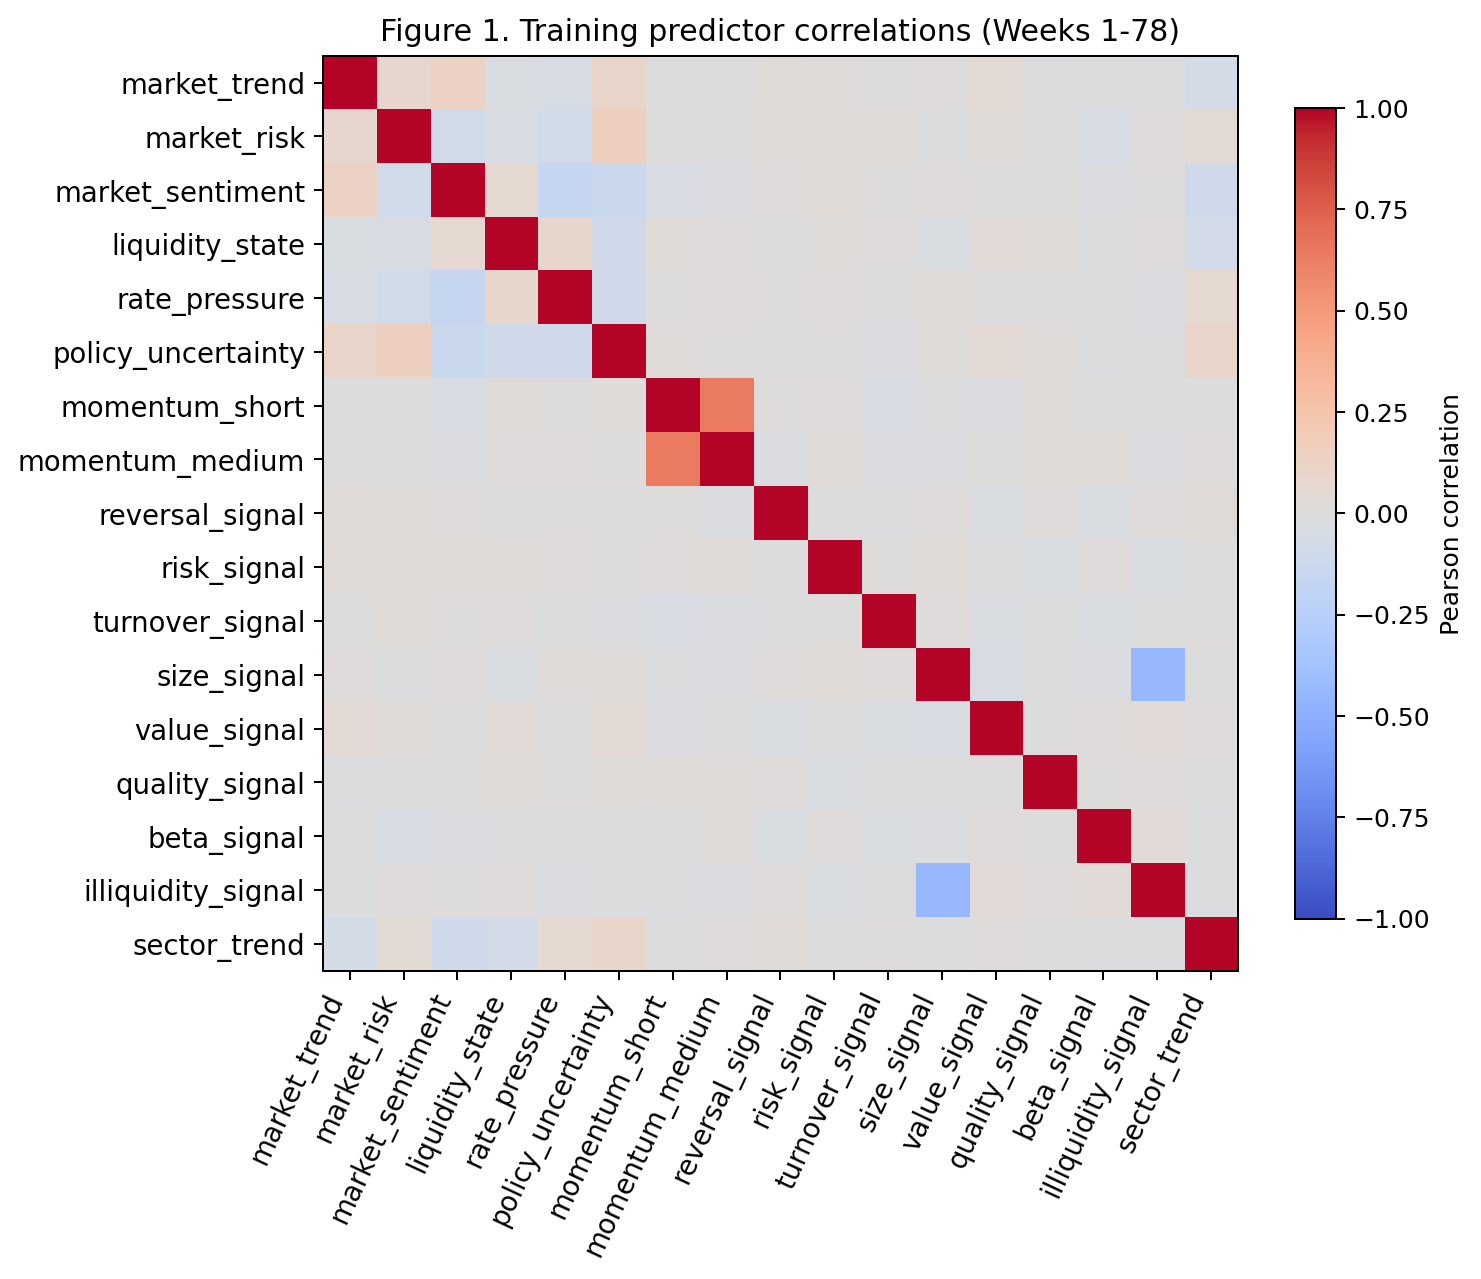

In [28]:
fig, ax = plt.subplots(figsize=(8.2, 7.8))
image = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(predictors)), predictors, rotation=65, ha="right", fontsize=11)
ax.set_yticks(range(len(predictors)), predictors, fontsize=11)
ax.set_title("Figure 1. Training predictor correlations (Weeks 1-78)")
fig.colorbar(image, ax=ax, shrink=0.75, label="Pearson correlation")
save_png(fig, "figure_1_correlations.png")
save_csv(corr.reset_index().rename(columns={"index": "predictor"}), "correlations.csv")
display(Image(filename=str(OUTPUT / "figure_1_correlations.png")))

**运行后怎样读：** Figure 1 应完整显示 17 个横纵轴标签和 −1 到 1 的色标；红偏同向、蓝偏反向。若轴字被截断，属于图表验收失败，不能只检查 PNG 存在。**所以呢：** 图展示结构，具体强相关系数由上一格给出。

### 1.7 亲手计算零预测、MSE 和样本外 R²


这里的均方误差（Mean squared error，MSE）衡量平均平方预测误差；样本外（Out-of-sample，OOS）指用于检验而非拟合模型的样本。

零预测永远给 $\hat y=0$，等于预测总收益恰好是无风险收益。它与 Q5 购买 80 股的等权组合完全不同。

$$
\mathrm{MSE}=\frac{1}{N}\sum_{i=1}^{N}(y_i-\hat y_i)^2
$$

$$
R^2_{\mathrm{OOS}}=1-\frac{\sum_i(y_i-\hat y_i)^2}{\sum_i y_i^2}
$$

$N$ 是同一组验证行的数量 2,080；$y$ 是真实超额收益，$\hat y$ 是预测。真实 0.03、预测 0.01 时，该行平方误差是 0.0004。若模型平方误差和是零预测的 1.02 倍，$R^2=-0.02$，表示比零预测差 2%，不是“准确率负数”。sklearn 的普通 `r2_score` 使用去均值基线，不能替代本题公式。

下面 `to_numpy()` 把一列转为数组；`**2` 是平方，`np.sum` 求和。`return` 把结果从短函数返回，以后所有模型都用同一指标。

In [31]:
def oos_r2(y: np.ndarray, prediction: np.ndarray) -> float:
    return float(1 - np.sum((y - prediction) ** 2) / np.sum(y**2))


y_valid = valid["y"].to_numpy()
zero_mse = np.mean(y_valid**2)
print(
    f"零预测验证 MSE：{zero_mse:.10f}；OOS R²：{oos_r2(y_valid, np.zeros(len(valid))):.6f}"
)

零预测验证 MSE：0.0030908984；OOS R²：0.000000


**运行后怎样读：** MSE 应为 0.0030908984，零预测 OOS R² 必为 0。MSE 的单位是平方小数收益，不能把它直接当百分数。**所以呢：** 同一个基线让线性和非线性模型的误差有可比性。

英文参考表述（笔记依据已保存结果整理，非教师答案）：Each block contains 80 stocks: 78 training weeks (6,240 rows), 26 validation weeks (2,080 rows), and 156 private weeks (12,480 rows). The training target mean is −0.00102268 and its sample standard deviation is 0.05650977, in decimal-return units. The training correlation between momentum_short and momentum_medium is 0.639994, excluding the self-correlation diagonal. Only training and validation outcomes are visible. A random stock-week split could put the same market week in training and validation and mix future periods into fitting, defeating the intended past-to-future check. The zero-excess-return forecast predicts y as zero, equivalent to predicting total return as rf_weekly; it is not the equal-weight portfolio. The zero-excess-return forecast has validation MSE 0.0030908984; rows stay in chronological whole-week blocks.


## Q2 · 让 OLS 与 LASSO 公平比较

目标是比较预测误差与系数，不是证明因果。brief p.2 指定训练期标准化、含截距、验证期选参数；理论对应 M03 线性机器学习。

<details><summary>Q2 英文原题全文（brief p.2）</summary>

Q2. OLS and LASSO (20 points)

Fit preprocessing and pooled OLS/LASSO on Weeks 1–78 with all 17 predictors and an intercept. Standardize with training means and standard deviations. Apply the same scaler to Weeks 79–104 and select settings there. Keep weeks intact in any additional time-based validation.

- Table 1: Prediction results. Report training MSE, validation MSE, and validation OOS $R^2$ for the zero forecast, OLS, and LASSO. Add Q3’s model later.
- Figure 2: LASSO penalty selection. Plot validation MSE over a small penalty grid. Report the selected penalty and number of nonzero coefficients.
- Table 2: Coefficients. Compare standardized OLS and selected LASSO coefficients for all 17 predictors, with a separate intercept row. Which signals does LASSO retain, and does selection improve validation accuracy?

Hint. Five to ten penalties suffice; choose the penalty with the lowest validation MSE. Larger penalties usually retain fewer signals. No estimation derivation is required.

</details>

中文读题：`same scaler` 要求验证期沿用训练均值与尺度，不能重新学习。截距单列；非零数只数 17 个斜率。参数要按验证误差选，不按训练误差或隐藏收益选。


### 2.1 标准化只学习训练期


特征原本的尺度不同，LASSO 惩罚会受尺度影响。标准化把每列改成离训练均值几个标准差。

$$
z=\frac{x-\mu_{\mathrm{train}}}{s_{\mathrm{train}}}
$$

$x$ 是原始特征，$\mu$ 和 $s$ 分别是训练均值与标准差。训练均值 10、标准差 2 时，验证值 14 转成 2。`fit` 学均值和尺度；`transform` 只套用。这里 StandardScaler 的尺度采用总体标准差（`ddof=0`），与 Q1 目标的样本标准差（`ddof=1`）是两个不同用途，不应混改。

In [35]:
scaler = StandardScaler().fit(train[predictors])
x_train = scaler.transform(train[predictors])
x_valid = scaler.transform(valid[predictors])
y_train = train["y"].to_numpy()
y_valid = valid["y"].to_numpy()
print("训练/验证矩阵：", x_train.shape, x_valid.shape)
print("训练列均值最大绝对值：", np.abs(x_train.mean(axis=0)).max())

训练/验证矩阵： (6240, 17) (2080, 17)
训练列均值最大绝对值： 7.287617802667694e-17


**运行后怎样读：** 形状应为 (6240, 17) 与 (2080, 17)，训练列均值接近 0（浮点误差级别）。验证列不要求均值为 0；若特意把验证集再标准化，就偷偷改变了尺度。**所以呢：** 验证数据只能接受训练期已经定好的处理规则。

### 2.2 拟合 OLS，看看截距和斜率


普通最小二乘（Ordinary least squares，OLS）找一组斜率，使训练平方误差最小。`LinearRegression()` 创建模型对象，默认含截距；`.fit(x_train, y_train)` 学参数。字典 `models` 保存名字与模型的对应；`coef_` 是 17 个斜率，`intercept_` 是所有标准化输入为 0 时的预测。

因为每列已经标准化，斜率表示“该变量高一个训练标准差时，其他输入固定，预测改变多少小数收益”。截距单列，不是第 18 个预测变量。

**笔记补充：一组系数怎样产生预测。** 假设只有一个标准化输入 $z$，模型选了截距 0.001、斜率 0.002。输入 $z=2$ 时，预测为 $0.001+0.002\times2=0.005$，即下周超额收益预测 0.5%。若真实值为 0.009，这行残差是 $0.009-0.005=0.004$，平方误差为 0.000016。OLS 比较候选截距和斜率在所有训练行上的平方误差和，挑总和最小的一组；多列时把各列的“斜率×输入”相加，再加截距。`fit` 求的是这一任务的参数，不是替每行另画一条线。

训练误差最小不保证以后的残差最小，所以验证期要另算同一误差。这里无需背矩阵求解；原题也不要求估计推导。


In [38]:
models: dict[str, object] = {"OLS": LinearRegression().fit(x_train, y_train)}
print(f'OLS 截距：{models["OLS"].intercept_:.8f}')
print("斜率数量：", len(models["OLS"].coef_))

OLS 截距：-0.00102268
斜率数量： 17


**运行后怎样读：** 应有 17 个斜率。训练得好还不代表未来预测得好；稍后 Table 1 会显示 OLS 的验证误差甚至超过零预测。**所以呢：** 拟合仅是候选的产生，不能立即宣布模型获胜。

### 2.3 用 8 个惩罚值选 LASSO


套索回归（Least absolute shrinkage and selection operator，LASSO）在线性误差之外惩罚斜率绝对值，较大的 `alpha` 通常压缩更多斜率至 0。它不是把“没用变量”机械删掉，而是在拟合与简单程度之间取舍。`max_iter` 是最多优化迭代数，`tol` 是收敛容差，均沿用基线。

循环逐个训练模型并预测同一验证集；`.append` 追加一条记录。`np.argmin` 返回最小误差所在的位置，再从列表拿出那一模型。选参数使用未舍入值，不能先四舍五入再比较。

**笔记补充：为什么惩罚可能把系数推到零。** sklearn 的 LASSO 把训练平均平方误差的一半，加上“alpha 乘所有斜率绝对值之和”来比较候选。截距不在这项惩罚中。

隔离一个输入的手算例：两行标准化输入为 −1、1，真实超额收益为 −0.02、0.02；固定截距为 0，用斜率 $b$ 预测。两行平方误差都为 $(b-0.02)^2$，所以平均平方误差也是这个值。取 $\alpha=0.005$，要最小化：

$$
J(b)=\tfrac12(b-0.02)^2+0.005\lvert b\rvert
$$

当 $b\geq0$，展开平方并配方可写成 $J(b)=\tfrac12(b-0.015)^2+0.0000875$。平方项最低为 0，因此这一段最小在 $b=0.015$；$b<0$ 时误差和惩罚都比取 0 更大，不会获胜。代回比较：$J(0)=0.0002$，$J(0.015)=0.0000875$，$J(0.02)=0.0001$，最优斜率比无惩罚的 0.02 小。

若 alpha 改为 0.03，非负段变成 $\tfrac12b^2+0.01b+0.0002$，每一新增正斜率都抬高目标，最小在 0。真实作业有 17 列、可学习截距及相关信号，不能用本例斜率替代真实拟合；这只是解释误差与惩罚怎样共同决定保留/压缩。


In [41]:
lasso_search = []
lasso_models = []
for penalty in PENALTIES:
    model = Lasso(alpha=float(penalty), max_iter=100000, tol=1e-7).fit(x_train, y_train)
    lasso_models.append(model)
    lasso_search.append(
        {
            "alpha": float(penalty),
            "validation_mse": float(
                mean_squared_error(y_valid, model.predict(x_valid))
            ),
            "nonzero": int(np.count_nonzero(model.coef_)),
        }
    )
best_lasso = int(np.argmin([item["validation_mse"] for item in lasso_search]))
models["LASSO"] = lasso_models[best_lasso]
save_csv(pd.DataFrame(lasso_search), "lasso_grid.csv")
lasso = lasso_search[best_lasso]
display(
    pd.DataFrame(lasso_search).style.format(
        {"alpha": "{:.8f}", "validation_mse": "{:.10f}"}
    )
)
print("选中 alpha：", f'{lasso["alpha"]:.8f}', "；非零斜率：", lasso["nonzero"])

,alpha,validation_mse,nonzero
0,0.00001000,0.0031538640,17
1,0.00002683,0.0031528126,17
2,0.00007197,0.0031500555,17
3,0.00019307,0.0031430651,16
4,0.00051795,0.0031263263,12
5,0.00138950,0.0030865289,7
6,0.00372759,0.0030722989,1
7,0.01000000,0.0031083096,0


选中 alpha： 0.00372759 ；非零斜率： 1


**运行后怎样读：** 应选择 alpha 0.00372759，保留 1 个非零斜率。若出现收敛警告，先记录并检查版本与缩放，不能忽略后宣称通过。**所以呢：** 模型复杂度由同一验证指标挑选，不能只展示最漂亮的一行。

### 2.4 画 Figure 2，理解对数横轴


惩罚从 0.00001 到 0.01，相差 1,000 倍，对数刻度能看清各档。`[item['alpha'] for item in lasso_search]` 是列表推导式：从每条记录提取 alpha；另一列提取验证 MSE。红点标出所选值，纵轴越低越好。

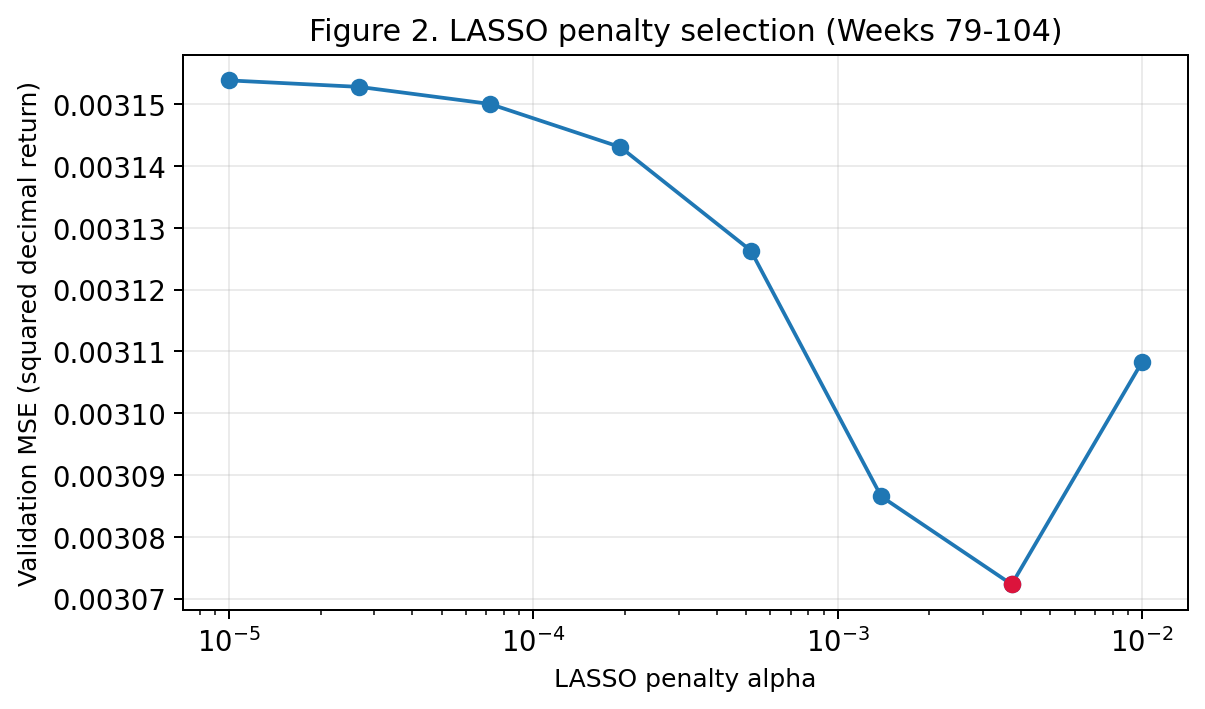

In [44]:
fig, ax = plt.subplots(figsize=(7.2, 4))
ax.plot(
    [item["alpha"] for item in lasso_search],
    [item["validation_mse"] for item in lasso_search],
    marker="o",
)
ax.scatter(
    lasso_search[best_lasso]["alpha"],
    lasso_search[best_lasso]["validation_mse"],
    color="crimson",
    zorder=3,
)
ax.set_xscale("log")
ax.set_xlabel("LASSO penalty alpha")
ax.set_ylabel("Validation MSE (squared decimal return)")
ax.set_title("Figure 2. LASSO penalty selection (Weeks 79-104)")
ax.tick_params(axis="both", labelsize=11)
ax.grid(alpha=0.25)
save_png(fig, "figure_2_lasso_penalty.png")
display(Image(filename=str(OUTPUT / "figure_2_lasso_penalty.png")))

**运行后怎样读：** Figure 2 的红点应落在最小验证 MSE 处。不要把“增大惩罚”理解为误差一定单调下降；过强惩罚也会丢信号。**所以呢：** 图解释为什么选这个惩罚，最终精确值仍看上一格表格。

### 2.5 生成 Table 2，解释保留的信号


`pd.DataFrame({...})` 用字典构造表，每个键是一列名。`['Intercept', *predictors]` 把截距名放最前，星号展开 17 个变量名；系数列采用完全相同的顺序。本次 quality_signal 系数 0.00274348 约等于 0.274348 个百分点。

先问 LASSO 留下谁，再与 OLS 比；不能把 0 系数推断为“经济上永远无关”。变量相关、惩罚和当前样本都影响选择。

In [47]:
table2 = pd.DataFrame(
    {
        "predictor": ["Intercept", *predictors],
        "ols_standardized_coefficient": [
            models["OLS"].intercept_,
            *models["OLS"].coef_,
        ],
        "lasso_standardized_coefficient": [
            models["LASSO"].intercept_,
            *models["LASSO"].coef_,
        ],
    }
)
save_csv(table2, "table_2_coefficients.csv")
display(
    table2.style.format(
        {
            "ols_standardized_coefficient": "{:.8f}",
            "lasso_standardized_coefficient": "{:.8f}",
        }
    )
)

,predictor,ols_standardized_coefficient,lasso_standardized_coefficient
0,Intercept,-0.00102268,-0.00102268
1,market_trend,0.00177806,0.00000000
2,market_risk,0.00199474,0.00000000
3,market_sentiment,-0.00167871,-0.00000000
4,liquidity_state,-0.00050169,-0.00000000
5,rate_pressure,-0.00275843,-0.00000000
6,policy_uncertainty,0.00149249,0.00000000
7,momentum_short,-0.00087024,0.00000000
8,momentum_medium,0.00143509,0.00000000
9,reversal_signal,0.00065004,0.00000000


**运行后怎样读：** 表应为 18 行（截距 + 17 变量），LASSO 只保留 quality_signal。系数是给定模型内的条件预测关系，不是干预公司质量的因果效果。**所以呢：** Q4 森林的重要性可能选出不同信号，二者回答的问题不同。

英文参考表述（笔记整理，非教师答案）：The scaler is fitted on training data only. LASSO selects alpha 0.00372759 and retains quality_signal; its validation MSE is 0.0030722989 versus 0.0031544950 for OLS. This is predictive selection, not a causal result. Table 1, Table 2 and Figure 2 preserve the common evaluation and candidate comparisons.


## Q3 · 非线性模型是否真的改善

森林可以表达阈值和交互：例如某信号只有超过阈值时才改变预测。多个树平均可降低单树的不稳定性，但数据少或噪声大时仍会过拟合。本节对应 brief p.2、M04；不为展示技术而增加额外模型。

<details><summary>Q3 英文原题全文（brief p.2）</summary>

Q3. One nonlinear model (15 points)

Fit either random forest or boosting with the same predictors and split. Explain when it could improve on a linear model.

- Model settings and selection. Compare settings by validation MSE. Report those tried and the selected specification.
- Table 1: Prediction results. Add the selected model and explain whether it improves validation prediction.

Hint. Try four to six settings. For random forest, vary depth or minimum leaf size at a fixed tree count. For boosting, vary tree count at a fixed learning rate and shallow depth. Set a random seed. Extra models are optional; complexity alone earns no credit.

</details>

中文读题：只需森林或 boosting 二选一，输入和切分要与 Q2 相同；本 Notebook 选择森林。`could improve` 是解释何种关系下可能改善，不是要求把实际负面结果改成改善。


### 3.1 在相同时间区间比较 5 组森林


固定 200 棵树与随机种子，只改变最大深度 `max_depth` 和每个叶节点至少容纳多少行 `min_samples_leaf`。`None` 表示不设最大深度，`n_jobs=-1` 使用多核。`**setting` 把字典中的两个键展开成命名参数。

较深的树能拟合更细的折点，也更容易学到训练噪声。每组都只能在训练期 `fit`，在验证期算 MSE。此格需要等待，看到 `[*]` 时不要重复点击运行。

**笔记补充：森林里的树怎样给一个新输入作预测。** 一棵回归树按“某列是否小于阈值”把训练行分到不同分支，每个最终叶节点用该叶训练目标的平均值作预测。选阈值时，比较分完后各叶“目标减叶均值”的平方误差和；不是凭想象挑分组。

用四行教学数据完整走一个小例，输入依次为 0、1、2、3，目标为 0、0、0.02、0.04。这里只演示一列、最多分一次、每叶至少 1 行，不能把它当真实 `min_samples_leaf=10` 的运行。

1. 阈值放 0.5：左叶只有目标 0，均值 0；右叶均值 0.02，右叶平方误差和为 $0.0004+0+0.0004=0.0008$。
2. 阈值放 1.5：左叶均值 0，右叶均值 0.03，误差和为 $0+0+0.0001+0.0001=0.0002$。
3. 阈值放 2.5：左叶均值约 0.00666667，右叶均值 0.04，误差和约 0.00026667。因此三者中选 1.5。新输入 2.5 走右分支，预测为 0.03。
4. 森林重复产生多棵树并平均预测。“有放回抽样”允许同一训练行被抽到多次，例如指定另一棵抽到行 0、1、2、2；按同样分法，其右叶均值为 0.02。两棵对新输入分别给 0.03、0.02，平均是 0.025。这是明确指定抽样的解释例，不是本次真实森林的两棵树。

真实代码每棵树从训练行有放回抽样，种子控制可重复性；本代码未传 `max_features`，所用 sklearn 默认每次分裂可看全部输入列，不能套成“一定每次只看少数特征”。深度/叶大小限制分裂，预测到叶便结束；200 棵树的结果再平均。多树可降低单树不稳定性，仍可能共同学到不延续的噪声，验证期必须另核。


In [51]:
forest_search = []
forest_models = []
for setting in FOREST_SETTINGS:
    model = RandomForestRegressor(
        n_estimators=200, random_state=SEED, n_jobs=-1, **setting
    ).fit(x_train, y_train)
    forest_models.append(model)
    forest_search.append(
        {
            "n_estimators": 200,
            **setting,
            "validation_mse": float(
                mean_squared_error(y_valid, model.predict(x_valid))
            ),
        }
    )
best_forest = int(np.argmin([item["validation_mse"] for item in forest_search]))
models["Random forest"] = forest_models[best_forest]
save_csv(pd.DataFrame(forest_search), "forest_grid.csv")
forest = forest_search[best_forest]
display(pd.DataFrame(forest_search).style.format({"validation_mse": "{:.10f}"}))
print("选中：", forest)

,n_estimators,max_depth,min_samples_leaf,validation_mse
0,200,5.000000,10,0.0038428017
1,200,8.000000,10,0.0039446124
2,200,12.000000,10,0.0038876442
3,200,8.000000,25,0.0040134832
4,200,nan,25,0.0039457232


选中： {'n_estimators': 200, 'max_depth': 5, 'min_samples_leaf': 10, 'validation_mse': 0.0038428017425883483}


**运行后怎样读：** 应选 max_depth=5、min_samples_leaf=10，验证 MSE 0.0038428017；模型更复杂但没有改善预测。这种负面结果正是题目要求解释的证据。保存表中 `max_depth` 的 `nan` 是表格把 `None` 与数值放同列后的显示，表示该候选不设最大深度，不是数据缺失或模型没训练。**所以呢：** 只有非线性规律足够稳定、样本足够且复杂度适当时，灵活性才可能转成泛化收益。

### 3.2 补齐 Table 1：预测误差与投资表现分开看


`predictions` 是两层字典：先按模型名，再按 training/validation 取预测数组。零预测用 `np.zeros`。循环逐一算训练 MSE、验证 MSE、本题 OOS R²；模型顺序与原报告一致。

这里只比较每一行收益数值的误差。Q5 将根据预测排序选股；排序与精确预测收益大小的目标不同，所以最小 MSE 不保证最高 Sharpe。

In [54]:
predictions = {
    "Zero": {"training": np.zeros(len(train)), "validation": np.zeros(len(valid))}
}
for name, model in models.items():
    predictions[name] = {
        "training": model.predict(x_train),
        "validation": model.predict(x_valid),
    }
table1 = []
for name, values in predictions.items():
    table1.append(
        {
            "model": name,
            "training_mse": float(mean_squared_error(y_train, values["training"])),
            "validation_mse": float(mean_squared_error(y_valid, values["validation"])),
            "validation_oos_r2": oos_r2(y_valid, values["validation"]),
        }
    )
save_csv(pd.DataFrame(table1), "table_1_prediction.csv")
display(
    pd.DataFrame(table1).style.format(
        {
            "training_mse": "{:.10f}",
            "validation_mse": "{:.10f}",
            "validation_oos_r2": "{:.6f}",
        }
    )
)

,model,training_mse,validation_mse,validation_oos_r2
0,Zero,0.0031938884,0.0030908984,0.000000
1,OLS,0.0031130152,0.0031544950,-0.020575
2,LASSO,0.0031648626,0.0030722989,0.006018
3,Random forest,0.0022572555,0.0038428017,-0.243264


**运行后怎样读：** 验证 MSE：Zero 0.0030908984、OLS 0.0031544950、LASSO 0.0030722989、森林 0.0038428017。LASSO 略优，森林最差；OLS/森林的 OOS R² 为负。**所以呢：** 用低训练误差宣传森林优于线性模型会与验证证据冲突。

英文参考表述（笔记整理，非教师答案）：The selected 200-tree forest uses depth 5, minimum leaf size 10 and seed 2026. Its validation MSE is 0.0038428017, worse than the linear candidates and zero forecast, despite its lower training error. The attempted settings remain reported rather than hiding negative results. A nonlinear model could improve on a linear model if stable thresholds or interactions matter and complexity is supported by enough training data; that improvement did not occur here. The tried depth/leaf pairs were (5,10), (8,10), (12,10), (8,25), and (unlimited,25), all with 200 trees and the same seed.


## Q4 · 固定森林，逐列检查依赖

官方 brief p.2 称 Class 5 的 drop-to-zero；现有本地 M04 也提供相关知识。这里只按题面实现，不把本次计算冒充尚未取得的后续课堂内容。

<details><summary>Q4 英文原题全文（brief p.2）</summary>

Q4. Characteristic importance (15 points)

Apply Class 5’s drop-to-zero method to the selected nonlinear model. Keep it fixed, set one standardized validation predictor to zero, and recalculate OOS $R^2$. Repeat for all 17 predictors.

- Figure 3: Characteristic importance. Importance is original OOS $R^2$ minus OOS $R^2$ after replacement. Plot the five largest values; retain negative values.
- Figure 4: Response profile. Vary the most important standardized predictor from its training 10th to 90th percentile. Hold other inputs at their validation values and average predictions.
- Comparison with LASSO. Explain one difference between these results and LASSO’s selected variables.

Hint. Standardized zero is the training mean. Use the same scaler for fitting and importance. Importance is predictive, not causal; correlated signals can overlap.

</details>

中文读题：`Keep it fixed` 决定不重训；`one` 决定一次只换一列，下一列从原始副本重新开始；`all 17` 决定不能只算图上五项；响应图仍用各行其他验证值，不把其他列全部设均值。


### 4.1 一列设为标准化零值，计算重要性


先用原始验证输入得到基准分数，再只改变第 $j$ 列。模型保持固定，不重新 `fit`。

$$
I_j = R^2_{\mathrm{base}} - R^2_{\mathrm{zero},j}
$$

`base` 是原验证输入下的 OOS R²；`zero,j` 是把第 $j$ 列标准化值全部换成 0 后的 OOS R²。标准化 0 对应**训练均值**，不是原始值 0。若 base = −0.24、zero,j = −0.30，重要性是 −0.24 − (−0.30) = +0.06；若替换后变为 −0.20，则重要性为 −0.04，必须保留负号。

`enumerate` 同时给出位置 `j` 和变量名。`x_valid.copy()` 创建独立副本，避免永久破坏原验证输入；`changed[:, j]` 表示所有行、第 j 列。减号顺序不能倒过来。

In [58]:
y_valid = valid["y"].to_numpy()
original = oos_r2(y_valid, models["Random forest"].predict(x_valid))
scores = []
for j, predictor in enumerate(predictors):
    changed = x_valid.copy()
    changed[:, j] = 0.0
    scores.append(
        {
            "predictor": predictor,
            "importance": original
            - oos_r2(y_valid, models["Random forest"].predict(changed)),
        }
    )
display(pd.DataFrame(scores).head().style.format({"importance": "{:.6f}"}))

,predictor,importance
0,market_trend,-0.109299
1,market_risk,0.008741
2,market_sentiment,-0.006497
3,liquidity_state,0.046827
4,rate_pressure,-0.179869


**运行后怎样读：** 这一格按字典原顺序显示前 5 个分数，尚未排序。可能出现负值：表示当前固定模型在这一验证期去掉该列反而更好。**所以呢：** 测量的是模型依赖，不是变量本身的真实因果作用，也不是重新训练后能保留多少准确度。

### 4.2 排序并画 Figure 3


`sorted(..., key=lambda item: item['importance'], reverse=True)` 按重要性从大到小排序。`lambda` 是临时的小函数，这里仅告诉排序器取哪一项。`scores[:5]` 切片取前五个，`reversed` 反转绘图顺序，让最高的条形在上方。所有 17 项保存到 CSV，不把负值裁成 0。

,predictor,importance
0,sector_trend,0.060893
1,liquidity_state,0.046827
2,market_risk,0.008741
3,policy_uncertainty,0.004856
4,risk_signal,0.004852
5,illiquidity_signal,0.003962
6,momentum_medium,0.001662
7,reversal_signal,0.001403
8,momentum_short,0.001130
9,beta_signal,0.000989


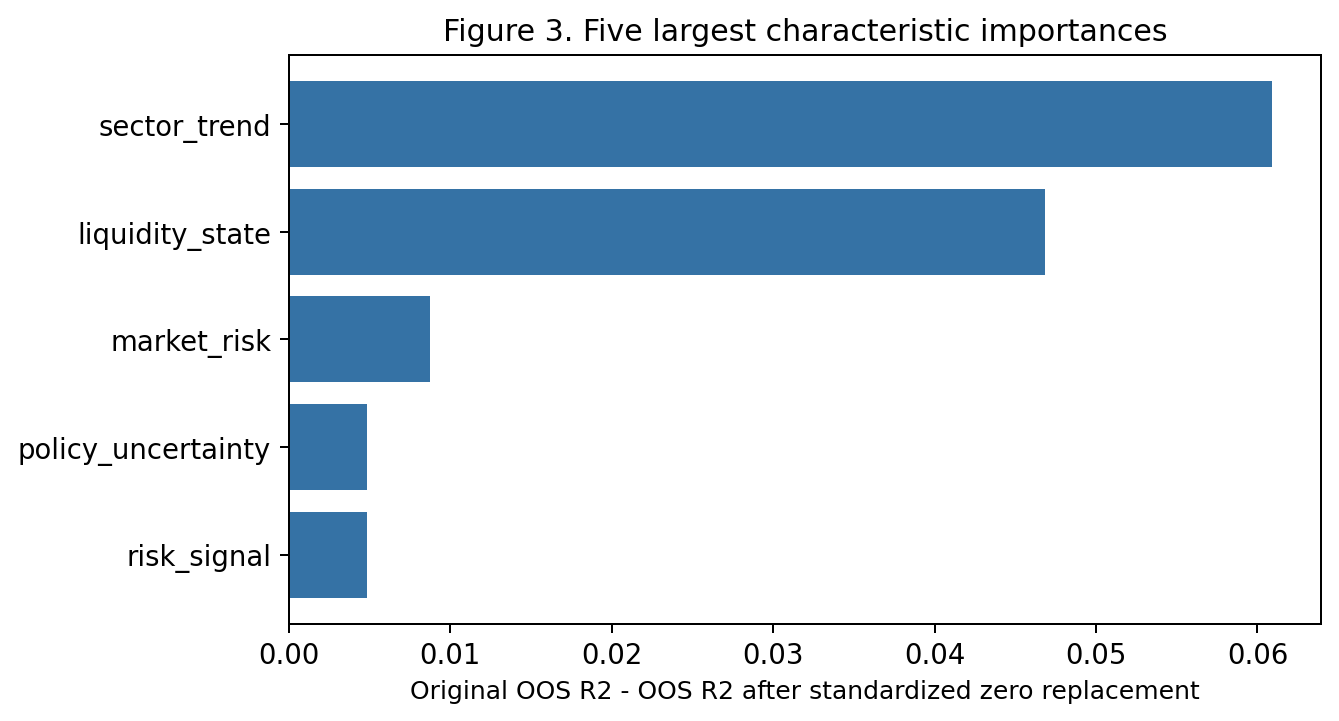

In [61]:
scores = sorted(scores, key=lambda item: item["importance"], reverse=True)
save_csv(pd.DataFrame(scores), "characteristic_importance_all.csv")
top = scores[:5]
fig, ax = plt.subplots(figsize=(7.4, 4.1))
ax.barh(
    [item["predictor"] for item in reversed(top)],
    [item["importance"] for item in reversed(top)],
    color="#3572A5",
)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Original OOS R2 - OOS R2 after standardized zero replacement")
ax.set_title("Figure 3. Five largest characteristic importances")
ax.tick_params(axis="both", labelsize=11)
save_png(fig, "figure_3_importance.png")
importance = scores
display(pd.DataFrame(scores).style.format({"importance": "{:.6f}"}))
display(Image(filename=str(OUTPUT / "figure_3_importance.png")))

**运行后怎样读：** 最高是 sector_trend，约 0.060893；其次 liquidity_state，0.046827。Figure 3 只画最大五项，CSV 保留全部。**所以呢：** “前五项”是展示限制，不是丢掉其余结果。

### 4.3 为响应曲线逐点替换输入


`predictors.index(lead)` 找最高重要性变量的位置。`np.quantile(..., 0.1/0.9)` 找训练标准化列的第 10/90 百分位，避免随意选极端范围；`np.linspace(...,41)` 在两个端点间均匀取 41 个值。

每次把所有验证行的该列设为同一个值，其他列仍是每行真实值，再对所有预测求平均。不是把所有输入都设成均值，也不是对真实收益求平均。

In [64]:
lead = top[0]["predictor"]
col = predictors.index(lead)
grid = np.linspace(
    np.quantile(x_train[:, col], 0.1), np.quantile(x_train[:, col], 0.9), 41
)
profile = []
for standardized_value in grid:
    changed = x_valid.copy()
    changed[:, col] = standardized_value
    profile.append(float(np.mean(models["Random forest"].predict(changed))))
print("变量：", lead, "；网格点数：", len(grid))
display(pd.DataFrame({"standardized_value": grid, "mean_prediction": profile}).head())

变量： sector_trend ；网格点数： 41


,standardized_value,mean_prediction
0,-1.289816,-0.005285
1,-1.228767,-0.005285
2,-1.167718,-0.005285
3,-1.106668,-0.005219
4,-1.045619,-0.006394


**运行后怎样读：** 应是 sector_trend、41 点。每个纵坐标是固定森林的平均预测超额收益，用小数收益表示。相关输入被单独替换可能形成少见组合，这是解释方法的局限。**所以呢：** 响应曲线只描述模型在这一操作下的行为。

### 4.4 画 Figure 4，并与 LASSO 对照


横轴用训练标准差单位，纵轴用平均预测下周超额收益；不得写成实际收益或因果影响。树通过阈值分段，所以曲线可能呈阶梯形。用规定的 Figure 4 编号，不挪给附录图。

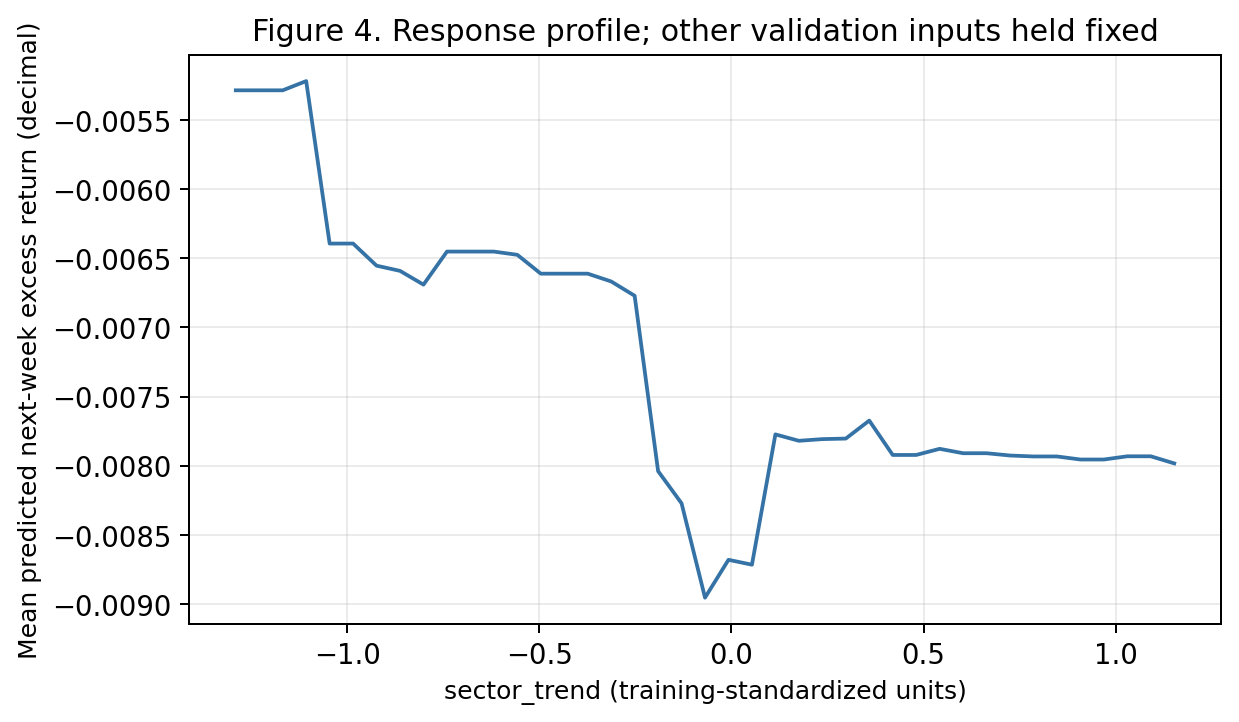

In [67]:
fig, ax = plt.subplots(figsize=(7.4, 4.1))
ax.plot(grid, profile, color="#3572A5")
ax.set_xlabel(f"{lead} (training-standardized units)")
ax.set_ylabel("Mean predicted next-week excess return (decimal)")
ax.set_title("Figure 4. Response profile; other validation inputs held fixed")
ax.tick_params(axis="both", labelsize=11)
ax.grid(alpha=0.25)
save_png(fig, "figure_4_response_profile.png")
save_csv(
    pd.DataFrame({"standardized_value": grid, "mean_prediction": profile}),
    "response_profile.csv",
)
display(Image(filename=str(OUTPUT / "figure_4_response_profile.png")))

**运行后怎样读：** 曲线总体下降并有台阶。LASSO 留 quality_signal，森林依赖 sector_trend，并不矛盾：前者是在惩罚下进行联合线性选择，后者是在固定非线性模型内逐列替换；相关变量还会分摊依赖。**所以呢：** 不能跨方法把两种数值当成统一的“真重要性排名”。

英文参考表述（笔记整理，非教师答案）：The forest remains fixed while each of 17 standardized validation columns is replaced by zero. Its leading dependence is sector_trend, whereas LASSO retains quality_signal. Figure 4 averages the forest’s predictions as that leading input varies over its training 10th–90th percentile range; neither result identifies a causal effect.


## Q5 · 预测转成持仓，先验证再冻结

本节对应 brief p.3。多头只持非负仓位；多空价差只用来比较高低预测组，不能把负权重写进提交文件。每周 80 股按预测降序，同分按 asset_id 升序，前 16 只每只权重 1/16 = 0.0625。

<details><summary>Q5 英文原题全文与指标约定（brief p.3）</summary>

Q5. Forecasts and portfolios (15 points)

Each validation week, rank all 80 stocks by predicted excess return, breaking ties by ascending asset_id. Apply both rules to each model:

- Long-short: equally weight the top 16 and short the bottom 16. The spread is the top group’s average return minus the bottom group’s average return.
- Long-only: equally weight the top 16, with zero elsewhere (within the 10% position cap).

Table 3: Validation portfolios. For each model, report the mean weekly long-short spread and the long-only portfolio’s annualized Sharpe ratio, information ratio versus equal weight, and maximum drawdown. Add the 80-stock equal-weight benchmark (N/A for its long-short spread). Does the best prediction model produce the best portfolio?

Final portfolio choice and risk. Choose a model and long-only rule from validation evidence: keep the top-16 rule or propose another. Explain your choice and identify or add its row in Table 3. Report its largest validation-week sector weight, naming the sector and week, and discuss one material risk. Refit preprocessing and the model on Weeks 1–104, then keep both fixed. Use each private week’s predictors to form weights for Weeks 105–260.

Weight constraints. Weights must be nonnegative, sum to 100%, and not exceed 10% per stock. Rebalance each of the 156 private weeks, starting from equal weights at the end of Week 104. Ignore transaction costs. Long-short results belong in the report, not the weight file.

Portfolio measures. Use 52 weeks per year and sample standard deviations. Weekly returns are $r_p$ for the portfolio, $r_f$ for the risk-free asset, and $r_{EW}$ for the rebalanced 80-stock equal-weight portfolio:

$$
\mathrm{Sharpe}=\sqrt{52}\frac{\operatorname{mean}(r_p-r_f)}{\operatorname{sd}(r_p-r_f)},\qquad
\mathrm{IR}=\sqrt{52}\frac{\operatorname{mean}(r_p-r_{EW})}{\operatorname{sd}(r_p-r_{EW})}
$$

For maximum drawdown, start wealth at 1 and compound total returns. Report the largest percentage fall from a previous peak as a nonpositive number. For grading, set ratios with standard deviation below $10^{-12}$ to zero, including equal weight’s information ratio against itself.

</details>

中文读题：各模型先按同一 top16 规则比较，最终规则才允许有依据地另选；`then keep both fixed` 指最终重拟合后的缩放器与模型不再根据隐藏期变化。只做多 CSV 和报告里的多空指标是两种交付，不能混写。


### 5.1 把风险指标写成可读的小函数


Sharpe 衡量超过无风险收益的平均回报相对于波动，信息比率（Information ratio，IR）改为超过 80 股等权收益的主动回报。

$$
\mathrm{Sharpe}=\sqrt{52}\frac{\overline{r_p-r_f}}{s(r_p-r_f)}
$$

$$
\mathrm{IR}=\sqrt{52}\frac{\overline{r_p-r_{EW}}}{s(r_p-r_{EW})}
$$

$r_p$ 为组合总收益，$r_f$ 为无风险收益，$r_{EW}$ 为每周再平衡的等权总收益，横线是 26 周平均，$s$ 为样本标准差。假设周超额均值 0.01、样本标准差 0.02，年化 Sharpe 为 $\sqrt{52}\times0.01/0.02\approx3.605551$。这是换算，不是保证未来年收益。题目规定标准差低于 $10^{-12}$ 时比率为 0。

财富从 1 开始逐周乘以 $(1+r_p)$，回撤是财富相对于此前最高点的跌幅。

$$
D_t=\frac{W_t}{\max_{s\leq t}W_s}-1,\qquad \mathrm{MDD}=\min_t D_t
$$

$W_t$ 是累计财富；从 1.10 跌到 1.00，回撤是 −0.090909，即 −9.0909%。`np.cumprod` 累乘，`np.maximum.accumulate` 记录历史最高财富，`np.r_[1.0,...]` 把初始财富 1 放在最前。

In [71]:
def drawdown(returns: np.ndarray) -> tuple[float, np.ndarray, np.ndarray]:
    wealth = np.r_[1.0, np.cumprod(1.0 + returns)]
    peak = np.maximum.accumulate(wealth)
    path = wealth / peak - 1.0
    return float(path.min()), wealth, path


def ratio(returns: np.ndarray) -> float:
    sd = float(np.std(returns, ddof=1))
    return 0.0 if sd < 1e-12 else float(np.sqrt(52) * np.mean(returns) / sd)


def portfolio_metrics(
    total_returns: np.ndarray, rf: np.ndarray, ew: np.ndarray
) -> dict[str, float]:
    mdd, _, _ = drawdown(total_returns)
    return {
        "long_only_sharpe": ratio(total_returns - rf),
        "long_only_information_ratio": ratio(total_returns - ew),
        "long_only_max_drawdown": mdd,
    }


print("教学例子最大回撤：", f"{drawdown(np.array([0.10, -1/11]))[0]:.6f}")

教学例子最大回撤： -0.090909


**运行后怎样读：** 例子最大回撤应为 −0.090909。题目要求最大回撤报告非正数，越接近 0 跌幅越小；不能直接取总收益最差的一周替代。**所以呢：** 先锁定指标口径，后面才不会为喜欢的策略换定义。

### 5.2 明确排名与行业上限怎样执行


下面函数只做一件事：按预测挑 16 只。`np.lexsort((asset_id, -values))` 最后一个键优先，负预测实现从高到低；同分再按 ID 小到大。它返回的是当前位置，方便用 `.iloc` 或数组索引取股票。

不设行业上限时取前 16；设置 `sector_cap=6` 时逐个候选检查，同行业已经选了 6 个就跳过。`counts.get(sector,0)` 是读取计数，没有记录就从 0 开始；`break` 在凑满 16 个时结束循环。函数源码完整展示，没有把核心排序藏在外部脚本里。

图只画 `sector_cap` 已给定的行业约束分支；无行业约束时，函数直接返回排名前 16 个位置。箭头表示源码中的控制顺序，返回边表示继续找下一位，不是重新预测。

![行业上限选股的控制流程](figures/a01-review/pick-top16.svg)

图源：`figures/a01-review/pick-top16.mmd`；根据本 Notebook 的 `pick_top16` 代码绘制，属于笔记说明。

走图小例：已经选了 15 只，其中行业甲达到 cap=6。下一候选仍属甲，不能加入，沿“跳过”回到下一位；再下一候选属乙，乙原来只选了 2 只，加入后总数 16、乙变 3，结束循环并返回。若余下候选全在已满行业，循环耗尽仍只有 15 只，断言失败，不能造出第 16 只或悄悄少投。

本地行业上限额外改变“能否选入”的判断，但不改变按预测下降、同分按ID上升的顺序。若行业条件使全体80股中也凑不够16股，代码会在最后断言停止；不能把不足16个仓位当成满足原规则，或只跳过失败周。当前数据与既有输出能凑齐，不把这一已知样本结果推广成所有未来数据保证。


In [74]:
def pick_top16(
    subset: pd.DataFrame, values: np.ndarray, sector_cap: int | None = None
) -> np.ndarray:
    order = np.lexsort((subset["asset_id"].to_numpy(), -values))
    if sector_cap is None:
        return order[:16]
    picked: list[int] = []
    counts: dict[str, int] = {}
    sectors = subset["official_sector"].to_numpy()
    for position in order:
        sector = str(sectors[position])
        if counts.get(sector, 0) < sector_cap:
            picked.append(int(position))
            counts[sector] = counts.get(sector, 0) + 1
        if len(picked) == 16:
            break
    assert len(picked) == 16
    return np.asarray(picked)


print("函数已定义；下一格将逐周调用。")

函数已定义；下一格将逐周调用。


**运行后怎样读：** 这格只定义选股规则，不运行回测。每股 6.25% 小于 10% 上限；行业最多 6 个仓位意味着 37.5000% 上限。这个行业规则是团队的验证期拓展，不是教授强制要求。**所以呢：** 风险约束应能用明确可执行的规则说清楚。

### 5.3 三个模型逐周做多头与多空


外层循环换模型，内层 `groupby('week')` 换周。`positions = subset.index - valid.index.min()` 把原表行号转换成验证预测数组的位置。`actual[top].mean()` 是前 16 股实际总收益的平均；多空价差再减后 16 股平均。不使用隐藏期答案。

`weights = np.zeros(80)` 从全零开始，前 16 个位置填 1/16；`np.isclose` 容许浮点误差检查总和等于 1。列表存每周回报，最后转成数组传给刚刚讲解的小指标函数。

In [77]:
rows = []
weekly = []
chosen_weights = {}
for name in ["OLS", "LASSO", "Random forest"]:
    predicted = predictions[name]["validation"]
    long_only, spreads, equal_weight, rf_values = [], [], [], []
    for week, subset in valid.groupby("week", sort=True):
        positions = subset.index.to_numpy() - valid.index.min()
        values = predicted[positions]
        order = np.lexsort((subset["asset_id"].to_numpy(), -values))
        actual = subset["ret_next_week"].to_numpy()
        top = pick_top16(subset, values)
        bottom = order[-16:]
        weights = np.zeros(80)
        weights[top] = 1.0 / 16
        assert np.isclose(weights.sum(), 1) and np.max(weights) <= 0.10
        chosen_weights[(name, int(week))] = weights
        long_only.append(float(actual[top].mean()))
        spreads.append(float(actual[top].mean() - actual[bottom].mean()))
        equal_weight.append(float(actual.mean()))
        rf_values.append(float(subset["rf_weekly"].iloc[0]))
        weekly.append(
            {
                "model": name,
                "week": int(week),
                "forecast_date": subset["forecast_date"].iloc[0],
                "long_only_return": long_only[-1],
                "equal_weight_return": equal_weight[-1],
                "risk_free_return": rf_values[-1],
                "long_short_spread": spreads[-1],
            }
        )
    metrics = portfolio_metrics(
        np.array(long_only), np.array(rf_values), np.array(equal_weight)
    )
    rows.append(
        {
            "model_rule": f"{name} / top 16",
            "mean_weekly_long_short_spread": float(np.mean(spreads)),
            **metrics,
        }
    )
display(pd.DataFrame(rows).style.format(precision=6))

,model_rule,mean_weekly_long_short_spread,long_only_sharpe,long_only_information_ratio,long_only_max_drawdown
0,OLS / top 16,0.022008,4.453041,7.865440,-0.047750
1,LASSO / top 16,0.020343,4.292557,10.929279,-0.054877
2,Random forest / top 16,0.015343,3.459620,4.089961,-0.042986


**运行后怎样读：** 应出现 OLS、LASSO、Random forest 三行。OLS top-16 的 Sharpe 约 4.453041，精确结果看输出；每行还有周均多空价差、IR 和最大回撤。出现索引错配时必须停下，不可重新随机排序数据。**所以呢：** 比较的是同 26 周、同样选 16 股的策略。

### 5.4 加等权基准，选择候选模型


等权基准每周把 80 股各分 1/80；其相对于自己的主动收益恒为 0，因此 IR 为 0，多空价差填 N/A（`np.nan`），不能填一笔虚构交易。

先在三个 top-16 策略中按 Sharpe 降序，再用最大回撤作第二排序键，均用未舍入值。`.iloc[:3]` 只取三种模型，不让基准参与选模型；`.iloc[0]` 取排名第一行。

In [80]:
ref = pd.DataFrame(weekly).query("model == 'OLS'").sort_values("week")
ew = ref["equal_weight_return"].to_numpy()
rf = ref["risk_free_return"].to_numpy()
rows.append(
    {
        "model_rule": "80-stock equal weight",
        "mean_weekly_long_short_spread": np.nan,
        **portfolio_metrics(ew, rf, ew),
    }
)
ranking = (
    pd.DataFrame(rows)
    .iloc[:3]
    .sort_values(["long_only_sharpe", "long_only_max_drawdown"], ascending=False)
)
selected = ranking.iloc[0]["model_rule"].split(" / ")[0]
print("候选模型：", selected)
display(pd.DataFrame(rows).style.format(precision=6, na_rep="N/A"))

候选模型： OLS


,model_rule,mean_weekly_long_short_spread,long_only_sharpe,long_only_information_ratio,long_only_max_drawdown
0,OLS / top 16,0.022008,4.453041,7.865440,-0.047750
1,LASSO / top 16,0.020343,4.292557,10.929279,-0.054877
2,Random forest / top 16,0.015343,3.459620,4.089961,-0.042986
3,80-stock equal weight,N/A,1.780305,0.000000,-0.077666


**运行后怎样读：** 应选 OLS，尽管 Q2/Q3 最小预测 MSE 来自 LASSO。IR 又是 LASSO 较高，没有一个模型赢下所有指标。**所以呢：** 预测误差、排序收益与风险调整回报是不同目标，必须说明最后优先哪一个。

### 5.5 只增加一个有动机的风险检验


单股不过 10% 仍可能把大部分资金押在同一行业。基线 OLS top-16 曾有 87.5000% 集中在一个行业，因此测试“每行业最多 6 股”。依然按 OLS 预测顺序挑选，保留 16 股等权，不改变收益口径。

下面只对同一验证期重新计算这一个候选规则。它在看过验证结果后提出，属于探索，不是独立测试或事前注册策略；隐藏区间才是尚不可见的检验。

In [83]:
# One transparent risk check motivated by the top-16 sector concentration.
capped_returns, capped_rf, capped_ew = [], [], []
for week, subset in valid.groupby("week", sort=True):
    positions = subset.index.to_numpy() - valid.index.min()
    selected_positions = pick_top16(
        subset, predictions[selected]["validation"][positions], sector_cap=6
    )
    actual = subset["ret_next_week"].to_numpy()
    capped_returns.append(float(actual[selected_positions].mean()))
    capped_rf.append(float(subset["rf_weekly"].iloc[0]))
    capped_ew.append(float(actual.mean()))
    weekly.append(
        {
            "model": f"{selected} sector cap 6",
            "week": int(week),
            "forecast_date": subset["forecast_date"].iloc[0],
            "long_only_return": capped_returns[-1],
            "equal_weight_return": capped_ew[-1],
            "risk_free_return": capped_rf[-1],
            "long_short_spread": np.nan,
        }
    )
print("行业约束回测周数：", len(capped_returns))

行业约束回测周数： 26


**运行后怎样读：** 应有 26 个周收益。若少于 26，说明某些周被漏掉；不能只算成功选出股票的周。**所以呢：** 有依据的拓展既展示收益也展示代价，不能把验证期调优说成无偏估计。

### 5.6 保存 Table 3 并公开取舍


用相同指标加入行业约束行；每周明细另外保存，使表格可追查到各周。`.DataFrame(weekly)` 把逐周记录变成表。MSE 不是这里的选择指标，我们预先写明这一步比较 Sharpe 与回撤。

In [86]:
capped_metrics = portfolio_metrics(
    np.array(capped_returns), np.array(capped_rf), np.array(capped_ew)
)
rows.append(
    {
        "model_rule": f"{selected} / top 16; sector cap 6",
        "mean_weekly_long_short_spread": np.nan,
        **capped_metrics,
    }
)
table = pd.DataFrame(rows)
save_csv(table, "table_3_portfolios.csv")
save_csv(pd.DataFrame(weekly), "validation_weekly_portfolios.csv")
display(table.style.format(precision=6, na_rep="N/A"))

,model_rule,mean_weekly_long_short_spread,long_only_sharpe,long_only_information_ratio,long_only_max_drawdown
0,OLS / top 16,0.022008,4.453041,7.865440,-0.047750
1,LASSO / top 16,0.020343,4.292557,10.929279,-0.054877
2,Random forest / top 16,0.015343,3.459620,4.089961,-0.042986
3,80-stock equal weight,N/A,1.780305,0.000000,-0.077666
4,OLS / top 16; sector cap 6,N/A,4.764914,7.707589,-0.042543


**运行后怎样读：** Table 3 共 5 行：三个模型、等权、OLS 行业约束。约束改善 Sharpe 与回撤，但 IR 下降，报告必须保留这点。**所以呢：** “更好”要说清楚对哪个指标更好。

### 5.7 锁定最终规则


下面的 `if ... else ...` 是条件表达式：仅当行业约束同时提高 Sharpe，且最大回撤不更差，才选它；否则保留普通 top-16。最大回撤为非正值，因此 `>=` 表示更接近 0。

In [89]:
standard_metrics = next(
    row for row in rows if row["model_rule"] == f"{selected} / top 16"
)
selected_rule = (
    "top16-sector-cap6"
    if (
        capped_metrics["long_only_sharpe"] > standard_metrics["long_only_sharpe"]
        and capped_metrics["long_only_max_drawdown"]
        >= standard_metrics["long_only_max_drawdown"]
    )
    else "top16"
)
print("最终规则：", selected, selected_rule)

最终规则： OLS top16-sector-cap6


**运行后怎样读：** 应为 OLS / top16-sector-cap6。这个选择已在验证期发生，后续不能再根据隐藏表现挑规则。**所以呢：** 冻结规则后再重训，避免“边看盲测边改答案”。

### 5.8 核查行业集中度


逐周把同一行业的持仓权重相加，`groupby('sector')['weight'].sum()` 得到行业权重。`max(...,key=...)` 找所有周所有行业中最大值，同时保留周、日期和行业名。只报上限 37.5% 不够，题目要求实际最集中的周与行业。

In [92]:
concentration = []
for week, subset in valid.groupby("week", sort=True):
    if selected_rule == "top16-sector-cap6":
        positions = subset.index.to_numpy() - valid.index.min()
        picked = pick_top16(
            subset, predictions[selected]["validation"][positions], sector_cap=6
        )
        weights = np.zeros(80)
        weights[picked] = 1.0 / 16
    else:
        weights = chosen_weights[(selected, int(week))]
    sector_weight = (
        pd.DataFrame(
            {"sector": subset["official_sector"].to_numpy(), "weight": weights}
        )
        .groupby("sector")["weight"]
        .sum()
    )
    for sector, value in sector_weight.items():
        concentration.append(
            {
                "week": int(week),
                "forecast_date": subset["forecast_date"].iloc[0],
                "sector": sector,
                "sector_weight": float(value),
            }
        )
save_csv(pd.DataFrame(concentration), "validation_sector_weights.csv")
largest = max(concentration, key=lambda item: item["sector_weight"])
table3 = table
weekly = pd.DataFrame(weekly)
print(largest)

{'week': 79, 'forecast_date': '2023-01-06', 'sector': 'Commerce & Industry', 'sector_weight': 0.375}


**运行后怎样读：** 最大行业权重应为 0.375，Week 79、Commerce & Industry。行业一起下跌仍会造成损失；题目忽略交易成本，但真实交易不会免费。**所以呢：** 行业上限减轻集中，不等于投资安全或隐藏期收益有保证。

### 5.9 Figure A1：看财富路径而非只看一个比率


把最终规则和等权的每周总收益分别复利，从财富 1 开始；再画各自从历史高点回落的路径。`axes[0]` 是上图、`axes[1]` 是下图，共享横轴。Week 78 的点是验证开始前的初始财富，收益从 Week 79 开始。

这是解释风险的附录图，不占 Figure 1–4 编号，也不是独立新测试。

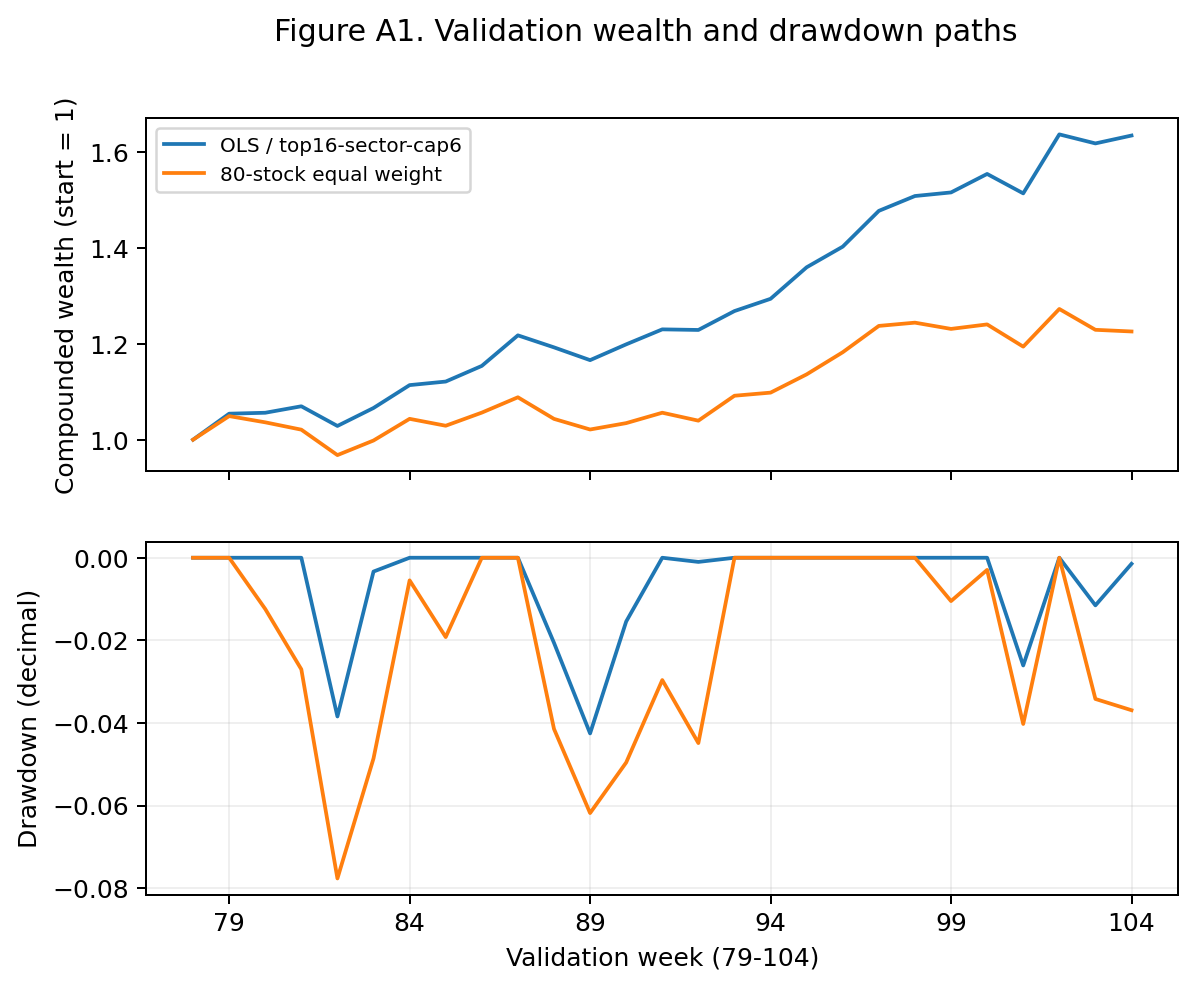

In [95]:
label = f"{selected} sector cap 6" if selected_rule == "top16-sector-cap6" else selected
chosen = weekly.loc[weekly["model"] == label].sort_values("week")
strategy = chosen["long_only_return"].to_numpy()
benchmark = chosen["equal_weight_return"].to_numpy()
_, strat_wealth, strat_dd = drawdown(strategy)
_, ew_wealth, ew_dd = drawdown(benchmark)
fig, axes = plt.subplots(2, 1, figsize=(7.4, 5.6), sharex=True)
x = np.arange(78, 105)
axes[0].plot(x, strat_wealth, label=f"{selected} / {selected_rule}")
axes[0].plot(x, ew_wealth, label="80-stock equal weight")
axes[0].set_ylabel("Compounded wealth (start = 1)")
axes[0].legend(fontsize=8)
axes[1].plot(x, strat_dd, label="Selected strategy")
axes[1].plot(x, ew_dd, label="Equal weight")
axes[1].set_ylabel("Drawdown (decimal)")
axes[1].set_xlabel("Validation week (79-104)")
axes[1].set_xticks([79, 84, 89, 94, 99, 104])
axes[1].grid(alpha=0.2)
fig.suptitle("Figure A1. Validation wealth and drawdown paths")
save_png(fig, "figure_A1_validation_paths.png")
display(Image(filename=str(OUTPUT / "figure_A1_validation_paths.png")))

**运行后怎样读：** Figure A1 应同时显示财富与回撤两幅图，验证期结束为 Week 104。图表让你看到中途回撤，不应仅凭终点较高就称“稳定获利”。**所以呢：** 附录服务于有证据的风险讨论。

英文参考表述（笔记整理，非教师答案）：LASSO has the best validation MSE, but OLS gives the higher top-16 Sharpe. The explored six-stocks-per-sector rule reduces concentration and improves Sharpe and drawdown in these 26 weeks, with a lower information ratio. Its largest validation sector weight is 0.375 in Commerce & Industry in Week 79. A sector shock remains a material risk even with the concentration cap, and ignored trading costs could reverse the apparent benefit. After selection, the scaler and OLS model are refitted once on Weeks 1–104 and kept fixed for Weeks 105–260. Each private week uses 16 weights of 0.06250000, with zero elsewhere, retaining all 80 columns and 156 template dates; weights are nonnegative, sum to one and stay below 0.10. Initial holdings are equal weight at the end of Week 104 and transaction costs are ignored, as required. This rule was explored using the same validation data and is not an independent test or a guarantee about private returns.


### 5.10 用可见的 104 周重训一次


模型和规则选定后，把训练与验证的可见标签合在一起重新拟合标准化器和最终模型。`.isin([...])` 判断分区名是否在给定列表。隐藏期只调用 `transform` 和 `predict`，不 `fit`。

为便于审计，代码保留三种模型的条件分支；本次 `selected == 'OLS'`，只会执行 OLS 分支。`elif` 表示上一条件不满足时再判断，`else` 是其余情况。这不是重新选择模型。

In [98]:
fit = frame.loc[frame["set"].isin(["training", "validation"])]
private = frame.loc[frame["set"] == "private_evaluation"]
scaler = StandardScaler().fit(fit[predictors])
x_fit = scaler.transform(fit[predictors])
x_private = scaler.transform(private[predictors])
y_fit = fit["y"].to_numpy()
if selected == "OLS":
    model = LinearRegression().fit(x_fit, y_fit)
elif selected == "LASSO":
    model = Lasso(alpha=lasso["alpha"], max_iter=100000, tol=1e-7).fit(x_fit, y_fit)
else:
    model = RandomForestRegressor(
        n_estimators=200,
        max_depth=forest["max_depth"],
        min_samples_leaf=forest["min_samples_leaf"],
        random_state=SEED,
        n_jobs=-1,
    ).fit(x_fit, y_fit)
print("最终训练行/隐藏行：", len(fit), len(private))

最终训练行/隐藏行： 8320 12480


**运行后怎样读：** 应为 8,320 / 12,480 行；前者对应 104×80，后者 156×80。用验证期重训是最终模型步骤，不可再拿先前验证指标宣称这次重训也经过独立检验。**所以呢：** 输出权重前严格区分模型选择与最终拟合。

### 5.11 读取官方模板，预测隐藏期


模板决定 156 个日期和 80 个股票代码的顺序。`template.columns[1:]` 跳过第一列日期；即使某股全程没买，也不能删列。`io.StringIO` 创建内存文本缓冲区，`csv.writer` 按 CSV 规则写表头和各行。

In [101]:
prediction = model.predict(x_private)
template = pd.read_csv(RELEASE / "submission_template_2026.csv")
tickers = template.columns[1:].tolist()
assert len(tickers) == 80 and len(template) == 156
output = io.StringIO(newline="")
writer = csv.writer(output, lineterminator="\n")
writer.writerow(template.columns)
print("模板形状：", template.shape, "；预测数量：", len(prediction))

模板形状： (156, 81) ；预测数量： 12480


**运行后怎样读：** 模板应为 (156, 81)，预测长度 12,480。没有隐藏期真实收益，所以不能在这里算隐藏 Sharpe。**所以呢：** 预测只决定持仓，不提供盲测分数。

### 5.12 逐周写出 16 个非零权重


`enumerate` 为每周提供模板行号。先找入选股票代码集合，再按模板的 ticker 顺序逐列写：入选 `0.06250000`，未选 `0.00000000`。字符串保留 8 位小数，避免输出格式依赖默认浮点显示。

每周先验证有 16 个不同 ticker，日期与官方模板相同。`writer.writerow` 每次写一整行，不把多空策略的负权重写入提交件。

In [104]:
for row_index, (week, subset) in enumerate(private.groupby("week", sort=True)):
    positions = subset.index.to_numpy() - private.index.min()
    picked = pick_top16(
        subset,
        prediction[positions],
        sector_cap=6 if selected_rule == "top16-sector-cap6" else None,
    )
    selected_tickers = set(subset.iloc[picked]["ticker"])
    assert len(selected_tickers) == 16
    date = template.iloc[row_index, 0]
    assert date == subset["forecast_date"].iloc[0]
    writer.writerow(
        [
            date,
            *(
                "0.06250000" if ticker in selected_tickers else "0.00000000"
                for ticker in tickers
            ),
        ]
    )
print("CSV 已在内存生成，尚未覆盖正式命名文件。")

CSV 已在内存生成，尚未覆盖正式命名文件。


**运行后怎样读：** 应无异常；每行 16×0.0625 = 1，其余 64 股为 0，单股不超过 0.1。若日期断言失败先核数据排序与模板，不要手工改日期。**所以呢：** 提交格式必须与分析策略逐周一致。

### 5.13 保存草稿，核权重文件哈希


SHA-256 是文件字节的指纹。相同数值但不同换行也可能得到不同指纹；本次要求与已有草稿字节完全一致。`hashlib.sha256(...).hexdigest()` 对完整字节计算指纹，`.upper()` 只把显示转为大写。

最终文件仍带 `DRAFT/LEAD_ID`，不因为计算跑通就换成正式件。

In [107]:
target = OUTPUT / "DRAFT_EF5560_LEAD_ID.csv"
atomic_write(target, output.getvalue())
weight_info = {
    "path": str(target),
    "selected_model": selected,
    "selected_rule": selected_rule,
    "fit_weeks": "1-104",
    "private_weeks": "105-260",
}
import hashlib

weight_sha = hashlib.sha256(target.read_bytes()).hexdigest().upper()
print(weight_sha)
assert weight_sha == "D7A74ECD2730FFC8790AB703BA6F6BA8EFCCB55BE752133C7645F347925ECCF8"

D7A74ECD2730FFC8790AB703BA6F6BA8EFCCB55BE752133C7645F347925ECCF8


**运行后怎样读：** 应显示指定的 D7A74E…ECCF8 指纹且断言通过。若失败先调查数值、版本、排序或文件格式差异，禁止为了通过而复制旧权重替代计算。**所以呢：** 重构教学不应悄悄改变原分析。

### 6.1 保存报告所需的结果结构


`results.json` 是报告构建器读取的汇总文件，保留原键名、表格和版本信息。`json.dumps(..., allow_nan=False)` 拒绝把非标准的 NaN 写入 JSON；Table 3 的 N/A 转为 `None`（JSON 的 null）。原始计算保留全精度，报告函数最后格式化。

这里只组织前面已经算出的结果，不隐藏新计算。下面可直接检查选模型、选规则、样本数是否正确。

In [110]:
summary = {
    "source_csv": str(RELEASE / "project_data_handout_2026.csv"),
    "n_rows": len(frame),
    "predictors": predictors,
    "split_counts": frame.groupby("set")
    .agg(
        weeks=("week", "nunique"), stocks=("asset_id", "nunique"), rows=("week", "size")
    )
    .to_dict("index"),
    "training_target_mean": float(train["y"].mean()),
    "training_target_sample_sd": float(train["y"].std(ddof=1)),
    "strongly_correlated_pair": {"first": pair[0], "second": pair[1], "r": pair[2]},
    "lasso_selected": lasso,
    "forest_selected": forest,
    "lasso_retained": table2.loc[
        (table2["predictor"] != "Intercept")
        & (table2["lasso_standardized_coefficient"].abs() > 1e-12),
        "predictor",
    ].tolist(),
    "most_important_characteristic": lead,
    "characteristic_importance_top5": importance[:5],
    "portfolio_model_selected": selected,
    "portfolio_rule_selected": selected_rule,
    "largest_validation_sector_weight": largest,
    "table_1": table1,
    "table_3": table3.astype(object).where(pd.notna(table3), None).to_dict("records"),
    "weights": weight_info,
    "versions": {
        "python": sys.version.split()[0],
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "sklearn": sklearn.__version__,
        "matplotlib": matplotlib.__version__,
    },
    "random_seed": SEED,
}
atomic_write(
    OUTPUT / "results.json",
    json.dumps(summary, ensure_ascii=False, indent=2, allow_nan=False) + "\n",
)

print(
    summary["n_rows"],
    summary["portfolio_model_selected"],
    summary["portfolio_rule_selected"],
)

20800 OLS top16-sector-cap6


**运行后怎样读：** 应为 20800、OLS、top16-sector-cap6。CSV 三表、5 张图、结果 JSON、权重都在 output。**所以呢：** Notebook 与报告共享一份计算结果，不维护第二套分析逻辑。

### 6.2 核查产物清单与关键约束


最后把完成标准写成可执行检查：三表必须都存在，五幅图必须非空，权重为 156×81，所有权重非负且单股不超过 10%。这只是自己的检查；打包时还必须调用老师的官方 checker。

In [113]:
required_outputs = [
    "table_1_prediction.csv",
    "table_2_coefficients.csv",
    "table_3_portfolios.csv",
    "figure_1_correlations.png",
    "figure_2_lasso_penalty.png",
    "figure_3_importance.png",
    "figure_4_response_profile.png",
    "figure_A1_validation_paths.png",
    "results.json",
    "DRAFT_EF5560_LEAD_ID.csv",
]
for name in required_outputs:
    assert (OUTPUT / name).is_file() and (OUTPUT / name).stat().st_size > 0, name
w = pd.read_csv(OUTPUT / "DRAFT_EF5560_LEAD_ID.csv").iloc[:, 1:]
assert w.shape == (156, 80)
assert np.isclose(w.sum(axis=1), 1).all()
assert (w >= 0).all().all() and (w <= 0.10).all().all()
assert (w.gt(0).sum(axis=1) == 16).all()
print("产物完整；156 周 × 80 股，逐周 16 个非零权重，自检通过。")

产物完整；156 周 × 80 股，逐周 16 个非零权重，自检通过。


**运行后怎样读：** 应看到自检通过。之后保存 Notebook，再按 Obsidian「开始这里」运行报告构建和打包；打包器从本 Notebook 生成清除输出的副本，不包含旧分析脚本。**所以呢：** 源码与阅读版仍是一份来源。

## 7 · 不看代码，自己解释一遍

1. 为什么不能随机打散股票周行？为什么隐藏答案不能补 0？
2. `fit`、`transform`、`predict` 分别做什么？标准化 0 是什么？
3. 为什么森林训练 MSE 更小，却不能说更会预测？
4. Q4 负重要性意味着什么？为什么不能推出因果？
5. 为什么选择 OLS 组合而非 MSE 最低的 LASSO？行业规则有什么代价？
6. 为什么 checker PASS 仍不等于“可提交”？

参考判断：① 时间泄漏；隐藏标签未公布。② 学参数、套转换、给预测；0 对应训练均值。③ 验证误差更差。④ 在当前固定模型和验证样本中，替换该列反而改善；不识别因果。⑤ 优先验证 Sharpe 与回撤，行业上限降低集中但 IR 下降，且策略用同一验证期选择，存在选择偏差。⑥ checker 只核格式与权重，不核团队身份、理解、最新要求、报告论断或隐藏收益。

**团队复核边界：** 数据为模拟样本，验证只有 26 周；重复用它调模型与规则会高估泛化表现。题目忽略交易成本，现实应用需检验成本、换手、跨时期稳健性。此处没有声称完成这些额外检验。本地DRAFT中的身份与表述不能冒充已上传版本。既有2026-10-21记录已见10/12提交，不重复催交；如要核已交附件、评分或进行另一次获授权交付，再核对应Canvas回执、当前要求与真实团队检查，不能由此Notebook替本人改状态。

<details><summary>提交要求与评分原文（brief p.4，历史版本保真）</summary>

Submit three files with the same lead student’s ID, replacing leadstudentid (e.g., 12345678):

1. Report: "EF5560_leadstudentid_report.pdf". At most eight pages including the cover,
   plus an optional one-page appendix. List all members’ names and student numbers on the
   cover. Use Q1–Q5 headings, page numbers, and the three result tables. Layout is your choice;
   "report_outline_2026.txt" is optional.
2. Weights: "EF5560_leadstudentid.csv".
   Follow "portfolio_weight_rules_2026.txt". Keep the template’s 156 dates and 80 ticker
   columns in order. Use decimal weights with at least eight decimal places and run either supplied
   checker. Equal weight is a valid example, not a required strategy.
3. Code appendix: "EF5560_leadstudentid_code.zip", at most 10 MB. Include R/Python
   scripts or notebooks and helper source files used for the report and weights. Exclude data and
   installed packages. No separate README is required.

Implementation details. End with the main script/notebook name, software/package versions, and
random seeds. Code is for verification; length and programming style are not graded.
Format and units. Export from Word, LaTeX, or similar software with selectable, copyable text
and tables. Use plots, not code/console screenshots. Label units: decimal returns, squared decimal
returns for MSE, and decimal OOS 𝑅 2 . Keep at least six significant digits for MSE and four decimal
places for other summary statistics; calculate from unrounded values.
AI use statement. AI coding assistance is allowed. End the report with the tools used and one or
two checks your team performed, or state that no AI tools were used.


Grading criteria

Component                                                                                     Points

Q1–Q5: 10 + 20 + 15 + 15 + 15                                                                     75
Implementation: software/package versions 2; random seeds 1; valid weight CSV 2                    5
Private investment performance: Sharpe 8; information ratio 6; maximum drawdown 6                 20

Total                                                                                            100
Correct analysis and clear interpretation earn credit even when results are negative.
For each private metric, rank valid submissions from worst to best and award equally spaced scores
from 50% to 100% of its points. Average tied ranks. If all tie or only one submission is valid, award
75%. Drawdown closer to zero ranks higher. Invalid files receive zero private-performance points.

</details>

上方英文原件将模板、软件版本、随机种子、可搜索PDF、精度、AI声明、团队实际检查和评分分开。隐藏绩效20分中Sharpe/IR/回撤分别8/6/6；按有效提交相对排名给各指标50%–100%的相应分数，同分平均、全同或只有一份有效时给75%，无效权重该部分0分。它不是预测本人的分数，当前真实评分未新核。
